# Week 3 — Data Quality & Pre-processing I
### SENG 42293 Big Data Analytics

This notebook walks through everything from the Week 3 lecture and slides, hands-on, on a
synthetic-but-realistic **messy customer dataset** built specifically to contain every
problem we discuss.

**Agenda**
1. Why data quality matters, and its dimensions
2. Building our sample dataset (deliberately messy)
3. Profiling the data
4. Missing data: types, visualization, handling
5. Duplicates & noisy data
6. Outliers: detecting and handling them
7. Encoding categorical variables
8. Normalization & standardization
9. Putting it all together: a reusable cleaning pipeline
10. Lab exercise for you


## 1. Why Data Quality Matters

A brilliant model trained on bad data still makes bad decisions — garbage in, garbage out.
A duplicated record can silently double a KPI; a missing value can silently bias an average.
This is where **Veracity** (one of the 5 V's of big data from Week 1) actually gets dealt with.

> A widely-cited estimate (IBM, 2016) puts the cost of poor-quality data to the US economy
> at **over $3 trillion a year**. Today's goal is to build the habits that catch these
> problems before they reach a model or a dashboard.

### The Data Quality Dimensions

| Dimension | Question it answers |
|---|---|
| **Completeness** | Is anything missing that should be there? |
| **Accuracy** | Does the data correctly reflect reality? |
| **Consistency** | Does the same fact agree across records? |
| **Timeliness** | Is the data current enough to be useful? |
| **Validity** | Does it conform to an expected format or range? |
| **Uniqueness** | Is each real-world fact recorded only once? |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import difflib
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
%matplotlib inline


## 2. Building Our Sample Dataset

We'll generate a synthetic **customer dataset** (`n=300`, plus injected duplicates) that
deliberately contains one issue for every dimension above:

| Issue injected | Column(s) | Dimension violated |
|---|---|---|
| ~25% missing, more likely for younger customers (MAR-style) | `Income` | Completeness |
| A handful of missing values | `City`, `SatisfactionLevel`, `SignupDate`, `PurchaseAmount` | Completeness |
| Age = 250 (typo) and two genuine extreme ages (91, 95) | `Age` | Accuracy / outliers |
| "USA" / "United States" / "U.S." used interchangeably | `Country` | Consistency |
| A handful of signups dated 2018 among mostly 2022–2024 data | `SignupDate` | Timeliness |
| One negative purchase amount | `PurchaseAmount` | Validity |
| 6 exact duplicate rows | (all columns) | Uniqueness |
| 5 near-duplicate rows (same email, one-letter name typo) | `Name` / `Email` | Uniqueness (the hard case) |

The random seed is fixed, so everyone gets the same dataset.


In [2]:
rng = np.random.default_rng(42)
n = 300

first_names = ["Aisha", "Kasun", "Nadeesha", "Ruwan", "Priya", "Chathura", "Dilani",
               "Saman", "Ishara", "Nuwan", "Tharindu", "Malki", "Ashen", "Kavindi", "Sanduni"]
last_names = ["Perera", "Fernando", "Silva", "Jayasuriya", "Bandara", "Gunawardena",
              "Wickramasinghe", "Rathnayake", "Dissanayake", "Herath"]

names = [f"{rng.choice(first_names)} {rng.choice(last_names)}" for _ in range(n)]
# append the row's future CustomerID to keep emails unique per person (avoids
# accidental collisions from the small name pool); the deliberately injected
# near-duplicate rows below will intentionally reuse an existing email.
emails = [f"{nm.lower().replace(' ', '.')}{i+1}@example.com" for i, nm in enumerate(names)]

ages = rng.normal(35, 9, n).round().astype(int)
ages = np.clip(ages, 18, 70)
# inject deliberate outliers: a data-entry typo and two genuine extreme values
outlier_idx = rng.choice(n, size=3, replace=False)
ages[outlier_idx[0]] = 250   # typo: impossible age -> Accuracy issue
ages[outlier_idx[1]] = 95    # genuine extreme value
ages[outlier_idx[2]] = 91    # genuine extreme value

incomes = rng.normal(58000, 9000, n).round(-2).astype(float)
# MAR-style missingness: younger customers are more likely to skip disclosing income
miss_prob = np.where(ages < 30, 0.65, 0.15)
incomes[rng.random(n) < miss_prob] = np.nan

country_choices = ["USA", "United States", "U.S.", "Sri Lanka", "Canada", "UK", "Australia"]
country_weights = [0.18, 0.12, 0.10, 0.30, 0.12, 0.10, 0.08]
countries = rng.choice(country_choices, size=n, p=country_weights)

city_choices = ["Colombo", "Kandy", "Galle", "Jaffna", "Negombo"]
cities = rng.choice(city_choices, size=n, p=[0.35, 0.25, 0.15, 0.15, 0.10]).astype(object)
cities[rng.random(n) < 0.04] = None

satisfaction_choices = ["Low", "Medium", "High"]
satisfaction = rng.choice(satisfaction_choices, size=n, p=[0.2, 0.5, 0.3]).astype(object)
satisfaction[rng.random(n) < 0.08] = None

start, end = pd.Timestamp("2022-01-01"), pd.Timestamp("2024-06-01")
signup_dates = start + pd.to_timedelta(rng.integers(0, (end - start).days, n), unit="D")
signup_dates = pd.Series(signup_dates)
stale_idx = rng.choice(n, size=4, replace=False)
signup_dates.iloc[stale_idx] = pd.Timestamp("2018-03-15")   # -> Timeliness issue
signup_dates = signup_dates.astype(object)
signup_dates[rng.random(n) < 0.05] = None

purchase = rng.gamma(shape=3.0, scale=55, size=n).round(2).astype(float)
purchase[rng.random(n) < 0.06] = np.nan
purchase[rng.choice(n)] = -42.50   # -> Validity issue

df = pd.DataFrame({
    "CustomerID": np.arange(1, n + 1),
    "Name": names,
    "Email": emails,
    "Age": ages,
    "Income": incomes,
    "Country": countries,
    "City": cities,
    "SatisfactionLevel": satisfaction,
    "SignupDate": signup_dates,
    "PurchaseAmount": purchase,
})

# inject exact duplicate rows -> Uniqueness issue
dup_rows = df.sample(n=6, random_state=7)
df = pd.concat([df, dup_rows], ignore_index=True)

# inject near-duplicate rows: same email, one-letter name typo -> the harder Uniqueness case
near_dup_source = df.sample(n=5, random_state=11).copy()

def typo(nm):
    parts = nm.split(" ")
    first = parts[0]
    if len(first) > 3:
        first = first[:2] + first[3] + first[2] + first[4:]  # swap two letters
    return first + " " + parts[1]

near_dup_source["Name"] = near_dup_source["Name"].apply(typo)
df = pd.concat([df, near_dup_source], ignore_index=True)

df = df.sample(frac=1, random_state=99).reset_index(drop=True)
print("Dataset shape:", df.shape)
df.head(10)


Dataset shape: (311, 10)


,CustomerID,Name,Email,Age,Income,Country,City,SatisfactionLevel,SignupDate,PurchaseAmount
0,200,Priya Jayasuriya,priya.jayasuriya200@example.com,39,51300.0,Sri Lanka,NaN,Medium,2023-06-22 00:00:00,256.52
1,114,Ashen Gunawardena,ashen.gunawardena114@example.com,37,67400.0,United States,Kandy,Low,2023-04-11 00:00:00,152.50
2,274,Dilani Gunawardena,dilani.gunawardena274@example.com,38,51800.0,UK,NaN,Medium,2022-01-06 00:00:00,95.87
3,219,Isahra Herath,ishara.herath219@example.com,57,60000.0,USA,Colombo,Low,2023-02-02 00:00:00,193.19
4,3,Dilani Dissanayake,dilani.dissanayake3@example.com,33,43100.0,UK,Colombo,Medium,2022-12-28 00:00:00,225.87
5,103,Dilani Silva,dilani.silva103@example.com,18,NaN,UK,Galle,Medium,2022-02-13 00:00:00,198.06
6,171,Nuwan Silva,nuwan.silva171@example.com,38,63700.0,USA,Galle,Medium,2023-10-07 00:00:00,122.60
7,122,Kasun Wickramasinghe,kasun.wickramasinghe122@example.com,23,NaN,Australia,Colombo,Medium,2022-07-14 00:00:00,228.72
8,113,Tharindu Jayasuriya,tharindu.jayasuriya113@example.com,33,57500.0,UK,Kandy,High,2022-08-18 00:00:00,173.67
9,16,Dilani Silva,dilani.silva16@example.com,32,64900.0,USA,Jaffna,High,2024-03-03 00:00:00,151.37


In [3]:
# Save a standalone copy of the raw messy dataset for reuse in later weeks
df.to_csv("messy_customers.csv", index=False)
print("Saved messy_customers.csv —", df.shape[0], "rows,", df.shape[1], "columns")


Saved messy_customers.csv — 311 rows, 10 columns


## 3. Profiling the Data

Before fixing anything, profile it — this is how you'd spot each dimension violation in a
real dataset. Compare this to the "Messy Data in Practice" table from the slides: the same
six problems all show up here, just at a scale where you need code (not eyeballing) to find them.


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         311 non-null    int64  
 1   Name               311 non-null    str    
 2   Email              311 non-null    str    
 3   Age                311 non-null    int64  
 4   Income             232 non-null    float64
 5   Country            311 non-null    str    
 6   City               292 non-null    str    
 7   SatisfactionLevel  292 non-null    str    
 8   SignupDate         298 non-null    object 
 9   PurchaseAmount     297 non-null    float64
dtypes: float64(2), int64(2), object(1), str(5)
memory usage: 24.4+ KB


In [5]:
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
CustomerID            0
Name                  0
Email                 0
Age                   0
Income               79
Country               0
City                 19
SatisfactionLevel    19
SignupDate           13
PurchaseAmount       14
dtype: int64


In [6]:
print("Exact duplicate rows:", df.duplicated().sum())


Exact duplicate rows: 6


In [7]:
# Consistency issue: the same country spelled three different ways
df["Country"].value_counts()


Country
Sri Lanka        99
USA              56
Australia        36
U.S.             34
United States    32
UK               29
Canada           25
Name: count, dtype: int64

In [8]:
# Accuracy issue: age=250 is impossible — describe() surfaces it via a wild max
df["Age"].describe()


count    311.000000
mean      36.128617
std       15.744621
min       18.000000
25%       29.000000
50%       36.000000
75%       41.000000
max      250.000000
Name: Age, dtype: float64

## 4. Missing Data — Types

Not all missing data is the same — the type of missingness determines whether a simple fix is safe:

- **MCAR** (Missing Completely At Random) — the chance of missingness has nothing to do with
  any value, observed or not. *Example: a sensor randomly drops 1% of readings.*
- **MAR** (Missing At Random) — missingness relates to *other observed* variables.
  *Example (ours): younger customers are more likely to skip disclosing `Income`.*
- **MNAR** (Missing Not At Random) — missingness relates to the *missing value itself* —
  the hardest, riskiest case. *Example: people with very high incomes decline to disclose them at all.*

### Visualizing the pattern


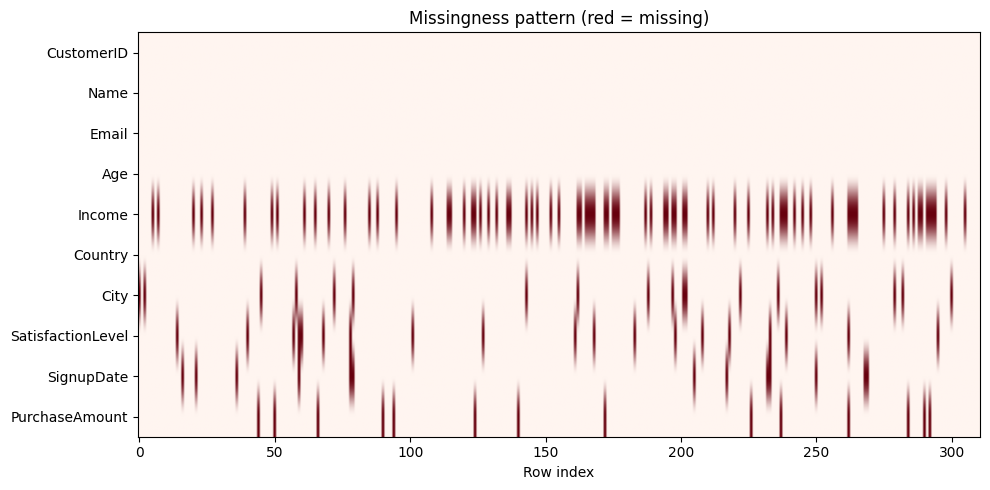

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(df.isnull().T, aspect="auto", cmap="Reds")
ax.set_yticks(range(len(df.columns)))
ax.set_yticklabels(df.columns)
ax.set_xlabel("Row index")
ax.set_title("Missingness pattern (red = missing)")
plt.tight_layout()
plt.show()


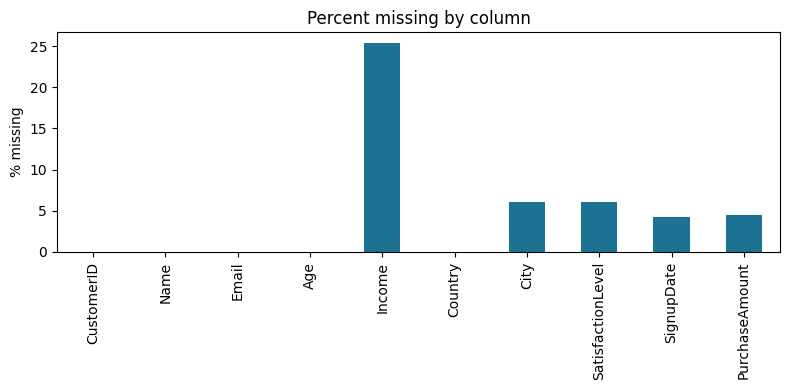

CustomerID            0.0
Name                  0.0
Email                 0.0
Age                   0.0
Income               25.4
Country               0.0
City                  6.1
SatisfactionLevel     6.1
SignupDate            4.2
PurchaseAmount        4.5
dtype: float64

In [10]:
pct_missing = (df.isnull().mean() * 100).round(1)
fig, ax = plt.subplots(figsize=(8, 4))
pct_missing.plot(kind="bar", ax=ax, color="#1C7293")
ax.set_ylabel("% missing")
ax.set_title("Percent missing by column")
plt.tight_layout()
plt.show()
pct_missing


### Handling Strategies

| Strategy | What it does | Best when | Risk |
|---|---|---|---|
| Listwise deletion | Drops any row with a missing value | Missingness is rare and MCAR | Wastes data; biases results if not MCAR |
| Mean/median imputation | Fills with the column average | Numeric, roughly symmetric data | Shrinks variance, hides uncertainty |
| Mode imputation | Fills with the most common category | Categorical columns | Over-represents the majority class |
| Forward/backward fill | Carries the nearest known value | Ordered time-series data | Wrong if the trend is actually changing |
| Model-based (k-NN, regression) | Predicts the value from other columns | Missingness matters and MAR holds | More complex, easy to overfit |
| Missing-indicator flag | Adds an `is_missing` column | Missingness itself may be informative | Doesn't fix the value, just flags it |


In [11]:
# Listwise deletion — only safe here because Age itself has no missing values;
# shown for comparison against the other strategies below.
df_listwise = df.dropna(subset=["Age"])
print("Rows after listwise deletion on Age:", len(df_listwise))


Rows after listwise deletion on Age: 311


In [12]:
# Mean/median imputation on a numeric column
income_median = df["Income"].median()
df["Income_imputed"] = df["Income"].fillna(income_median)
print("Income median used for imputation:", income_median)
df[["Income", "Income_imputed"]].head()


Income median used for imputation: 57800.0


,Income,Income_imputed
0,51300.0,51300.0
1,67400.0,67400.0
2,51800.0,51800.0
3,60000.0,60000.0
4,43100.0,43100.0


In [13]:
# Mode imputation on a categorical column
city_mode = df["City"].mode()[0]
df["City_imputed"] = df["City"].fillna(city_mode)
print("City mode used for imputation:", city_mode)


City mode used for imputation: Colombo


In [14]:
# Forward-fill on a time-ordered column
df_sorted = df.sort_values("SignupDate").copy()
df_sorted["SignupDate_ffill"] = df_sorted["SignupDate"].ffill()
print("Signup dates still missing after ffill:", df_sorted["SignupDate_ffill"].isnull().sum())


Signup dates still missing after ffill: 0


In [15]:
# Missing-indicator flag — keep the fact that a value WAS missing as its own feature
df["Income_was_missing"] = df["Income"].isnull().astype(int)
df[["Income", "Income_was_missing"]].head()


,Income,Income_was_missing
0,51300.0,0
1,67400.0,0
2,51800.0,0
3,60000.0,0
4,43100.0,0


## 5. Duplicates & Noisy Data

### Exact duplicates


In [16]:
print("Exact duplicate rows:", df.duplicated(keep=False).sum())
df_no_exact = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping exact duplicates:", df_no_exact.shape)


Exact duplicate rows: 12
Shape after dropping exact duplicates: (305, 13)


### Near-duplicates — the harder case

An exact-match dedupe misses records that are almost the same but not quite (a typo in the
name, say). One practical trick: group by a more stable field like `Email` and look for
groups with more than one row.


In [17]:
grouped = df_no_exact.groupby("Email")
near_dupe_emails = [email for email, group in grouped if len(group) > 1]
print("Emails appearing on more than one row (likely near-duplicates):", len(near_dupe_emails))
df_no_exact[df_no_exact["Email"].isin(near_dupe_emails)][["Name", "Email", "SignupDate"]].sort_values("Email")


Emails appearing on more than one row (likely near-duplicates): 5


,Name,Email,SignupDate
117,Chtahura Fernando,chathura.fernando261@example.com,2023-12-20 00:00:00
251,Chathura Fernando,chathura.fernando261@example.com,2023-12-20 00:00:00
64,Chathura Silva,chathura.silva190@example.com,2023-11-08 00:00:00
135,Chtahura Silva,chathura.silva190@example.com,2023-11-08 00:00:00
3,Isahra Herath,ishara.herath219@example.com,2023-02-02 00:00:00
120,Ishara Herath,ishara.herath219@example.com,2023-02-02 00:00:00
78,Kaivndi Fernando,kavindi.fernando195@example.com,None
247,Kavindi Fernando,kavindi.fernando195@example.com,None
23,Ruwan Rathnayake,ruwan.rathnayake242@example.com,2023-11-01 00:00:00
191,Ruawn Rathnayake,ruwan.rathnayake242@example.com,2023-11-01 00:00:00


In [18]:
# difflib gives a similarity ratio between two strings — useful when you don't
# have a shared key like Email to group on.
a, b = "Jon Smith", "John Smith"
similarity = difflib.SequenceMatcher(None, a, b).ratio()
print(f"Similarity between '{a}' and '{b}': {similarity:.2f}")


Similarity between 'Jon Smith' and 'John Smith': 0.95


### Noisy sensor data

Not all bad values are duplicates — sometimes a single reading is just wrong.


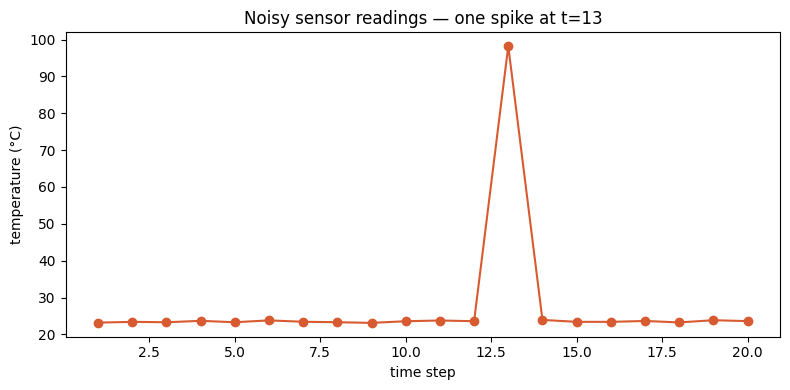

In [19]:
t = np.arange(1, 21)
readings = rng.normal(23.5, 0.3, 20)
readings[12] = 98.2  # a single sensor glitch

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, readings, marker="o", color="#D85A30")
ax.set_title("Noisy sensor readings — one spike at t=13")
ax.set_xlabel("time step")
ax.set_ylabel("temperature (°C)")
plt.tight_layout()
plt.show()


## 6. Outliers — Detecting Them

An outlier isn't always "bad data" — it could be an error (a typo, a unit mix-up, a sensor
glitch) or something genuine (a fraud transaction, a billionaire's income). Detection comes
before any decision to remove, cap, or keep.

### The IQR method


In [20]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f"Age: Q1={Q1}, Q3={Q3}, IQR={IQR}")
print(f"Bounds: [{lower}, {upper}]")

age_outliers = df[(df["Age"] < lower) | (df["Age"] > upper)]
age_outliers[["CustomerID", "Age"]]


Age: Q1=29.0, Q3=41.0, IQR=12.0
Bounds: [11.0, 59.0]


,CustomerID,Age
109,196,250
116,287,95
252,126,91


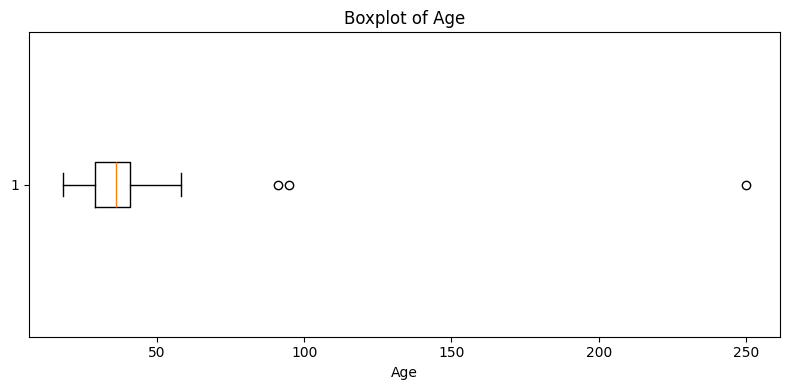

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(df["Age"].dropna(), vert=False)
ax.set_title("Boxplot of Age")
ax.set_xlabel("Age")
plt.tight_layout()
plt.show()


### The Z-score method

`z = (x - μ) / σ` — flag anything with `|z| > 3` (roughly 3 standard deviations out).


In [22]:
mean_age, std_age = df["Age"].mean(), df["Age"].std()
df["Age_zscore"] = (df["Age"] - mean_age) / std_age
z_outliers = df[df["Age_zscore"].abs() > 3]
z_outliers[["CustomerID", "Age", "Age_zscore"]]


,CustomerID,Age,Age_zscore
109,196,250,13.583775
116,287,95,3.739143
252,126,91,3.485088


### Handling strategies

| Strategy | What it does | Use when |
|---|---|---|
| **Remove** | Drop the record entirely | It's clearly an error — e.g. age = 250 |
| **Cap (winsorize)** | Clip the value to the nearest whisker bound | Extreme values are real but you want to limit their influence |
| **Transform** | Apply a log transform | Naturally skewed data, like income |
| **Flag & keep** | Add an `is_outlier` column; leave the value | The outlier itself might be the signal — e.g. fraud |


In [23]:
# Remove — for the clear data-entry error
df_clean_age = df[df["Age"] <= upper].copy()
print("Rows after removing Age > upper bound:", len(df_clean_age))


Rows after removing Age > upper bound: 308


In [24]:
# Cap — for the genuine-but-extreme values
df["Age_capped"] = df["Age"].clip(lower=lower, upper=upper)
df.loc[age_outliers.index, ["Age", "Age_capped"]]


,Age,Age_capped
109,250,59
116,95,59
252,91,59


In [25]:
# Transform — log-transform a skewed numeric column
df["Income_log"] = np.log1p(df["Income_imputed"])
df[["Income_imputed", "Income_log"]].head()


,Income_imputed,Income_log
0,51300.0,10.845466
1,67400.0,11.118415
2,51800.0,10.855165
3,60000.0,11.002117
4,43100.0,10.671301


In [26]:
# Flag & keep
df["Age_is_outlier"] = ((df["Age"] < lower) | (df["Age"] > upper)).astype(int)
df[["Age", "Age_is_outlier"]].head()


,Age,Age_is_outlier
0,39,0
1,37,0
2,38,0
3,57,0
4,33,0


## 7. Encoding Categorical Variables

- **Nominal** (no order — e.g. `City`) → **one-hot encoding**. No false ranking is introduced.
- **Ordinal** (has order — e.g. `SatisfactionLevel`) → **ordinal encoding**, preserving rank.

Mistake to avoid in each direction: label-encoding a nominal column as 0,1,2 invents a false
order; one-hot-encoding an ordinal column throws away real order information.


In [27]:
city_onehot = pd.get_dummies(df["City_imputed"], prefix="City").astype(int)
city_onehot.head()


,City_Colombo,City_Galle,City_Jaffna,City_Kandy,City_Negombo
0,1,0,0,0,0
1,0,0,0,1,0
2,1,0,0,0,0
3,1,0,0,0,0
4,1,0,0,0,0


In [28]:
satisfaction_map = {"Low": 0, "Medium": 1, "High": 2}
df["Satisfaction_ordinal"] = df["SatisfactionLevel"].map(satisfaction_map)
df[["SatisfactionLevel", "Satisfaction_ordinal"]].head()


,SatisfactionLevel,Satisfaction_ordinal
0,Medium,1.0
1,Low,0.0
2,Medium,1.0
3,Low,0.0
4,Medium,1.0


## 8. Normalization & Standardization

- **Min-max scaling**: `x' = (x - min) / (max - min)` — rescales to [0, 1]
- **Z-score standardization**: `x' = (x - μ) / σ` — mean 0, standard deviation 1

**Rule of thumb**: if your model computes a distance or a gradient (k-NN, k-means, logistic
regression, neural nets), scale your features. Tree-based models (random forests, gradient
boosting) generally don't need it.


In [29]:
mm = MinMaxScaler()
df["Income_minmax"] = mm.fit_transform(df[["Income_imputed"]])

ss = StandardScaler()
df["Income_standardized"] = ss.fit_transform(df[["Income_imputed"]])

df[["Income_imputed", "Income_minmax", "Income_standardized"]].head()


,Income_imputed,Income_minmax,Income_standardized
0,51300.0,0.330171,-0.809995
1,67400.0,0.635674,1.262954
2,51800.0,0.339658,-0.745617
3,60000.0,0.495256,0.310170
4,43100.0,0.174573,-1.865782


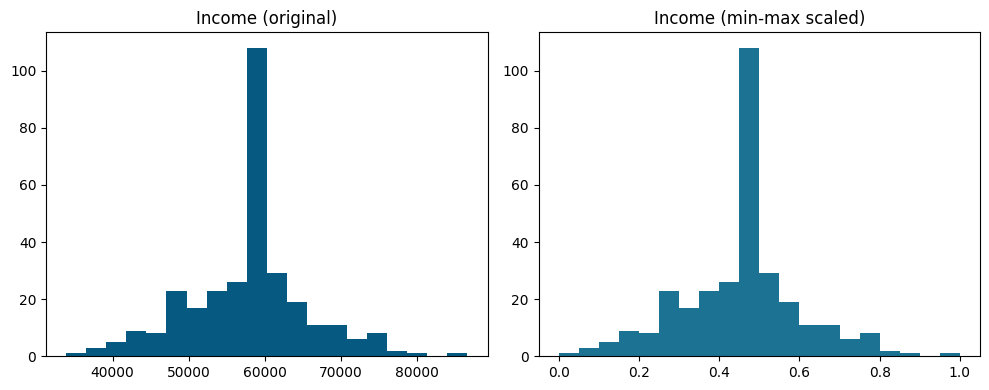

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df["Income_imputed"], bins=20, color="#065A82")
axes[0].set_title("Income (original)")
axes[1].hist(df["Income_minmax"], bins=20, color="#1C7293")
axes[1].set_title("Income (min-max scaled)")
plt.tight_layout()
plt.show()


## 9. Putting It All Together: A Cleaning Pipeline

One function per concern, composed into a single `clean_pipeline`. Each function prints what
it did and how many rows remain — the running commentary a markdown cell would give you, made
executable.


In [31]:
def standardize_country(value):
    if pd.isna(value):
        return value
    mapping = {"USA": "United States", "U.S.": "United States", "United States": "United States"}
    return mapping.get(value, value)


def handle_missing_values(frame):
    """Impute numeric columns with the median, categoricals with the mode,
    and drop rows where SignupDate itself is missing (we need it downstream)."""
    frame = frame.copy()
    frame["Income"] = frame["Income"].fillna(frame["Income"].median())
    frame["City"] = frame["City"].fillna(frame["City"].mode()[0])
    frame["SatisfactionLevel"] = frame["SatisfactionLevel"].fillna(frame["SatisfactionLevel"].mode()[0])
    frame["PurchaseAmount"] = frame["PurchaseAmount"].fillna(frame["PurchaseAmount"].median())
    frame = frame.dropna(subset=["SignupDate"])
    return frame


def remove_duplicates(frame):
    """Drop exact duplicates, ignoring CustomerID (which is unique by construction
    even for a duplicated person)."""
    return frame.drop_duplicates(subset=[c for c in frame.columns if c != "CustomerID"]).copy()


def fix_invalid_values(frame):
    """Standardize country spelling and drop rows with an impossible (negative) purchase."""
    frame = frame.copy()
    frame["Country"] = frame["Country"].apply(standardize_country)
    return frame[frame["PurchaseAmount"] >= 0]


def handle_outliers(frame, column, method="cap"):
    """IQR-based outlier handling — 'remove' drops them, 'cap' winsorizes them."""
    frame = frame.copy()
    q1, q3 = frame[column].quantile(0.25), frame[column].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if method == "remove":
        frame = frame[(frame[column] >= lo) & (frame[column] <= hi)]
    elif method == "cap":
        frame[column] = frame[column].clip(lower=lo, upper=hi)
    return frame


def encode_categoricals(frame):
    """One-hot encode the nominal City column; ordinal-encode SatisfactionLevel."""
    frame = frame.copy()
    frame = pd.get_dummies(frame, columns=["City"], prefix="City")
    frame["SatisfactionLevel"] = frame["SatisfactionLevel"].map({"Low": 0, "Medium": 1, "High": 2})
    return frame


def scale_numeric_features(frame, columns):
    """Z-score standardize the given numeric columns."""
    frame = frame.copy()
    scaler = StandardScaler()
    frame[columns] = scaler.fit_transform(frame[columns])
    return frame


def clean_pipeline(raw_df):
    print("Starting rows:", len(raw_df))
    out = handle_missing_values(raw_df)
    print("After missing-value handling:", len(out))
    out = remove_duplicates(out)
    print("After duplicate removal:", len(out))
    out = fix_invalid_values(out)
    print("After fixing invalid values:", len(out))
    out = handle_outliers(out, "Age", method="remove")
    print("After outlier removal (Age):", len(out))
    out = encode_categoricals(out)
    out = scale_numeric_features(out, ["Age", "Income", "PurchaseAmount"])
    print("Final shape:", out.shape)
    return out


In [32]:
raw = df[["CustomerID", "Name", "Email", "Age", "Income", "Country", "City",
          "SatisfactionLevel", "SignupDate", "PurchaseAmount"]].copy()

cleaned = clean_pipeline(raw)
assert cleaned.drop(columns=["SignupDate"]).isnull().sum().sum() == 0, "no missing values should remain"
cleaned.head()


Starting rows: 311
After missing-value handling: 298
After duplicate removal: 292
After fixing invalid values: 291
After outlier removal (Age): 288
Final shape: (288, 14)


,CustomerID,Name,Email,Age,Income,Country,SatisfactionLevel,SignupDate,PurchaseAmount,City_Colombo,City_Galle,City_Jaffna,City_Kandy,City_Negombo
0,200,Priya Jayasuriya,priya.jayasuriya200@example.com,0.439047,-0.831215,Sri Lanka,1,2023-06-22 00:00:00,0.965339,True,False,False,False,False
1,114,Ashen Gunawardena,ashen.gunawardena114@example.com,0.214654,1.232712,United States,0,2023-04-11 00:00:00,-0.172636,False,False,False,True,False
2,274,Dilani Gunawardena,dilani.gunawardena274@example.com,0.326850,-0.767118,UK,1,2022-01-06 00:00:00,-0.792166,True,False,False,False,False
3,219,Isahra Herath,ishara.herath219@example.com,2.458584,0.284075,United States,0,2023-02-02 00:00:00,0.272511,True,False,False,False,False
4,3,Dilani Dissanayake,dilani.dissanayake3@example.com,-0.234132,-1.882407,UK,1,2022-12-28 00:00:00,0.630030,True,False,False,False,False


Notice: `remove_duplicates` only catches **exact** duplicates — the 5 near-duplicate rows
(the ones with a typo'd name) are still in there. That's intentional: fuzzy deduplication is
a separate, harder step (Section 5), not something a generic pipeline does safely on its own
— merging two genuinely different "Chathura Silva"s would be a real mistake.


## 10. Lab Exercise for You

Using `messy_customers.csv` (or the `df` already in memory), extend this notebook:

- [ ] **Missing data**: try k-NN imputation on `Income` (`sklearn.impute.KNNImputer`) and
  compare the resulting distribution to the median-imputed version above.
- [ ] **Near-duplicates**: extend the email-grouping approach to also catch near-duplicates
  that *don't* share an email — use `difflib.SequenceMatcher` on the `Name` column instead,
  and decide on a similarity threshold.
- [ ] **Outliers**: repeat the IQR and Z-score analysis on `Income` or `PurchaseAmount` instead
  of `Age`. Do the two methods agree on which rows are outliers?
- [ ] **Encoding**: `Country` is nominal with 7 categories after cleaning. One-hot encode it,
  and justify in a markdown cell why this is (or isn't) a cardinality concern.
- [ ] **Scaling**: add a third scaled version of `Income` — `RobustScaler` — and explain in a
  markdown cell why it might behave differently from `StandardScaler` on this particular
  column (hint: think about what's still in there before you remove outliers).
- [ ] **Deliverable**: for each task above, add a markdown cell justifying *why* you chose the
  method you did — the reasoning matters as much as the code.

### Wrap-up & Next Week

**Today's key takeaways**
- Data quality has concrete, checkable dimensions — not just a vague "is it good?"
- Missing data isn't one problem — MCAR/MAR/MNAR changes what's safe to do about it
- Outliers require judgment: error or genuine signal?
- Encoding and scaling choices depend on what's downstream, not on habit

**Next week: Data Quality & Pre-processing II**
- Semi-structured data: JSON/XML, schema-on-read vs. schema-on-write
- Distributed pre-processing with Spark
- Feature engineering at scale
